<a href="https://colab.research.google.com/github/metrosmash/Inference_session_DSN_AI_Bootcamp_2026/blob/main/DSN_Resume_Skills_Audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Real-Time ML: Resume Skills Audit (notebook edition)
**DSN AI Bootcamp 2026 · Real-Time Machine Learning: Building and Deploying an Inference System · Olalekan Akinsande**

Everything runs in this notebook:

| Part | What happens |
|---|---|
| 1. Setup | Install and import packages |
| 2. Build | Skills taxonomy, shared feature function, synthetic training data |
| 3. Train + deploy | Train the shortlisting model, save it as an artifact, load it into an inference engine |
| 4. Read documents | Read PDF / DOCX / TXT, extract skills, experience, education and location |
| 5. Skills audit | Score one resume against one job description, show gaps and the skills that would help most |
| 6. Upload | **Upload a resume and a job description**, then click *Run skills audit* |
| 7. Cohort audit | Audit many resumes against one job (a program-level view) |
| 8. Optional | Serve the same engine as a live API from inside the notebook |

**Quick start:** run *Kernel → Restart & Run All*, then scroll to Part 6 and upload your files.
Sample files are created in `sample_files/` so the notebook works even before you upload anything.

> Training data is synthetic. The model learns what (simulated) employers shortlist, so treat scores as a teaching demo, not a hiring decision.

## Part 1 · Setup

In [3]:
# Run once per environment (skip if already installed)
%pip install -q scikit-learn pandas numpy joblib matplotlib pypdf python-docx ipywidgets reportlab

In [4]:
%matplotlib inline
import io, json, math, re, time, warnings
from datetime import date
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
SAMPLES = Path("sample_files"); SAMPLES.mkdir(exist_ok=True)
CURRENT_YEAR = date.today().year
print("Ready. Artifacts ->", ART.resolve())

Ready. Artifacts -> /content/artifacts


## Part 2 · Build
### 2.1 Skills taxonomy
One shared vocabulary. Resumes say *"MS Excel"*, *"MySQL"* or *"Kobo Toolbox"*; the model needs `excel`, `sql`, `survey_tools`.
In production this would be a maintained framework (ESCO, O*NET or a national skills framework).

In [5]:
SKILLS = [
    # digital & data
    "excel", "sql", "python", "data_analysis", "power_bi", "statistics", "data_entry", "data_visualization",
    "machine_learning", "monitoring_evaluation", "survey_tools",
    "web_development", "javascript", "graphic_design", "digital_marketing", "social_media",
    "content_writing", "it_support", "networking",
    # business & finance
    "bookkeeping", "accounting_software", "mobile_money_ops", "sales", "customer_service",
    "inventory_management", "procurement", "business_planning", "financial_literacy",
    # agriculture
    "agronomy", "poultry_management", "irrigation", "post_harvest_handling", "agribusiness",
    "extension_services", "aquaculture",
    # technical & green trades
    "electrical_installation", "solar_pv", "plumbing", "welding", "carpentry", "motor_mechanics",
    # logistics, health, creative
    "logistics", "driving", "warehouse_ops", "community_health", "first_aid",
    "fashion_design", "photography", "video_editing",
    # foundational
    "communication", "teamwork", "problem_solving", "english_writing", "project_management",
]
IDX = {s: i for i, s in enumerate(SKILLS)}

# phrase as it appears in documents -> canonical skill
SYNONYMS = {
    "ms excel": "excel", "microsoft excel": "excel", "spreadsheet": "excel", "spreadsheets": "excel",
    "pivot tables": "excel", "vlookup": "excel", "google sheets": "excel",
    "mysql": "sql", "postgresql": "sql", "postgres": "sql", "t-sql": "sql", "sql server": "sql", "bigquery": "sql",
    "python3": "python", "pandas": "python", "numpy": "python", "jupyter": "python",
    "data analytics": "data_analysis", "data analyst": "data_analysis", "analysing data": "data_analysis",
    "analyzing data": "data_analysis", "analyse data": "data_analysis", "analyze data": "data_analysis",
    "powerbi": "power_bi", "power bi": "power_bi", "dax": "power_bi",
    "data visualisation": "data_visualization", "dashboards": "data_visualization", "dashboard": "data_visualization",
    "tableau": "data_visualization", "looker studio": "data_visualization",
    "spss": "statistics", "stata": "statistics", "regression": "statistics", "statistical analysis": "statistics",
    "scikit-learn": "machine_learning", "sklearn": "machine_learning", "predictive modelling": "machine_learning",
    "predictive modeling": "machine_learning",
    "m&e": "monitoring_evaluation", "monitoring and evaluation": "monitoring_evaluation",
    "monitoring & evaluation": "monitoring_evaluation", "meal": "monitoring_evaluation",
    "kobo toolbox": "survey_tools", "kobotoolbox": "survey_tools", "kobocollect": "survey_tools", "odk": "survey_tools",
    "surveycto": "survey_tools", "survey design": "survey_tools",
    "html": "web_development", "css": "web_development", "frontend": "web_development", "react": "javascript",
    "canva": "graphic_design", "photoshop": "graphic_design", "figma": "graphic_design",
    "seo": "digital_marketing", "facebook ads": "digital_marketing", "google ads": "digital_marketing",
    "copywriting": "content_writing", "computer repair": "it_support", "help desk": "it_support",
    "quickbooks": "accounting_software", "sage": "accounting_software", "pos operations": "mobile_money_ops",
    "pos agent": "mobile_money_ops", "crm": "customer_service", "fish farming": "aquaculture",
    "poultry": "poultry_management", "solar installation": "solar_pv", "solar": "solar_pv",
    "electrician": "electrical_installation", "electrical wiring": "electrical_installation",
    "mechanic": "motor_mechanics", "tailoring": "fashion_design", "chw": "community_health",
    "written english": "english_writing", "report writing": "english_writing", "proposal writing": "english_writing",
    "stakeholder engagement": "communication", "presentation skills": "communication", "presentations": "communication",
    "communication skills": "communication", "team player": "teamwork", "collaboration": "teamwork",
    "critical thinking": "problem_solving", "project coordination": "project_management", "dispatch": "logistics",
}
# canonical names also count as phrases ("data_analysis" -> "data analysis")
PHRASES = {s.replace("_", " "): s for s in SKILLS}
PHRASES.update(SYNONYMS)
PHRASES = dict(sorted(PHRASES.items(), key=lambda kv: -len(kv[0])))   # longest first

COURSES = {
    "excel": "Excel for Work (2 wks)", "sql": "SQL Foundations (3 wks)", "python": "Python for Data (6 wks)",
    "data_analysis": "Data Analysis Bootcamp (4 wks)", "power_bi": "Power BI Dashboards (2 wks)",
    "statistics": "Practical Statistics (4 wks)", "data_visualization": "Data Storytelling & Visualisation (2 wks)",
    "machine_learning": "Intro to Machine Learning (6 wks)", "monitoring_evaluation": "M&E Fundamentals (3 wks)",
    "survey_tools": "Digital Data Collection with Kobo/ODK (1 wk)", "digital_marketing": "Digital Marketing Essentials (3 wks)",
    "solar_pv": "Solar PV Installer Certificate (8 wks)", "bookkeeping": "Bookkeeping for SMEs (3 wks)",
    "accounting_software": "QuickBooks / Sage Basics (2 wks)", "agribusiness": "Agribusiness Management (4 wks)",
    "customer_service": "Customer Service Excellence (1 wk)", "project_management": "Project Management Basics (3 wks)",
    "communication": "Workplace Communication (1 wk)", "english_writing": "Business & Report Writing (2 wks)",
}
def course_for(skill):
    return COURSES.get(skill, f"{skill.replace('_', ' ').title()} short course")

_NAMES = {"sql": "SQL", "power_bi": "Power BI", "solar_pv": "Solar PV", "it_support": "IT support",
          "monitoring_evaluation": "M&E", "data_visualization": "Data visualisation", "english_writing": "English / report writing"}
def pretty(skill):
    return _NAMES.get(skill, skill.replace("_", " ").capitalize())

print(f"{len(SKILLS)} skills, {len(PHRASES)} recognised phrases")

54 skills, 141 recognised phrases


### 2.2 One feature function, used in training **and** inference
If training and inference compute features differently, the model looks good offline and underperforms live (*training/serving skew*).

In [6]:
FEATURES = ["core_coverage", "optional_coverage", "n_core_missing", "cosine_sim", "exp_gap",
            "exp_ok", "edu_gap", "location_ok", "n_candidate_skills"]
EDU = {"secondary": 0, "tvet": 1, "ond": 1, "hnd": 2, "bsc": 2, "msc": 3}
EDU_LABEL = {"secondary": "Secondary (SSCE)", "tvet": "TVET / trade certificate", "ond": "OND / Diploma",
             "hnd": "HND", "bsc": "Bachelor's degree", "msc": "Master's or higher"}

def skill_vector(skills):
    v = np.zeros(len(SKILLS), dtype=np.float32)
    for s in skills:
        v[IDX[s]] = 1.0
    n = np.linalg.norm(v)
    return v / n if n else v

def pair_features(cand, job):
    cs, core, opt = set(cand["skills"]), set(job["core_skills"]), set(job["optional_skills"])
    exp_gap = cand["years_experience"] - job["min_experience"]
    return {
        "core_coverage": len(cs & core) / max(len(core), 1),
        "optional_coverage": len(cs & opt) / max(len(opt), 1),
        "n_core_missing": len(core - cs),
        "cosine_sim": float(skill_vector(cs) @ skill_vector(core | opt)),
        "exp_gap": exp_gap,
        "exp_ok": int(exp_gap >= 0),
        "edu_gap": EDU.get(cand["education"], 0) - EDU.get(job["min_education"], 0),
        "location_ok": int(job["state"] == "Remote" or job["state"] == cand["state"]),
        "n_candidate_skills": len(cs),
    }

### 2.3 Synthetic training data
Jobseekers, job posts and **employer shortlisting outcomes** (the label). Real projects would use historical application outcomes from a job platform or program.

In [7]:
STATES = ["Lagos", "FCT", "Kano", "Oyo", "Rivers", "Kaduna", "Enugu", "Ogun"]
ROLES = {  # role: (core skills, optional skills, min years, min education)
    "Data Analyst": (["excel", "sql", "data_analysis"], ["power_bi", "python", "statistics", "communication", "data_visualization"], 1, "bsc"),
    "Junior Data Scientist": (["python", "statistics", "sql"], ["data_analysis", "machine_learning", "power_bi", "problem_solving"], 2, "bsc"),
    "M&E Assistant": (["excel", "data_analysis", "monitoring_evaluation"], ["statistics", "survey_tools", "english_writing", "project_management"], 1, "bsc"),
    "Data Entry Clerk": (["data_entry", "excel"], ["communication", "teamwork", "survey_tools"], 0, "secondary"),
    "Frontend Developer": (["web_development", "javascript"], ["graphic_design", "problem_solving", "teamwork"], 1, "ond"),
    "IT Support Technician": (["it_support", "networking"], ["customer_service", "problem_solving"], 0, "ond"),
    "Digital Marketing Officer": (["digital_marketing", "social_media", "content_writing"], ["graphic_design", "data_analysis", "communication"], 1, "ond"),
    "Graphic Designer": (["graphic_design"], ["social_media", "photography", "video_editing"], 0, "secondary"),
    "Bookkeeper": (["bookkeeping", "accounting_software", "excel"], ["financial_literacy", "communication"], 1, "ond"),
    "POS / Mobile Money Agent": (["mobile_money_ops", "customer_service"], ["financial_literacy", "sales"], 0, "secondary"),
    "Sales Representative": (["sales", "customer_service", "communication"], ["digital_marketing", "driving"], 0, "secondary"),
    "Customer Care Agent": (["customer_service", "communication"], ["english_writing", "problem_solving", "it_support"], 0, "secondary"),
    "Procurement Assistant": (["procurement", "inventory_management", "excel"], ["communication", "logistics"], 1, "ond"),
    "Farm Supervisor": (["agronomy", "irrigation"], ["post_harvest_handling", "teamwork", "agribusiness"], 1, "tvet"),
    "Poultry Farm Manager": (["poultry_management", "agribusiness"], ["bookkeeping", "teamwork"], 2, "tvet"),
    "Agric Extension Agent": (["extension_services", "agronomy", "communication"], ["driving", "english_writing"], 1, "ond"),
    "Aquaculture Technician": (["aquaculture"], ["post_harvest_handling", "agribusiness"], 0, "tvet"),
    "Solar PV Installer": (["solar_pv", "electrical_installation"], ["problem_solving", "driving"], 0, "tvet"),
    "Electrician": (["electrical_installation"], ["solar_pv", "teamwork"], 1, "tvet"),
    "Auto Mechanic": (["motor_mechanics"], ["welding", "customer_service"], 1, "tvet"),
    "Welder / Fabricator": (["welding"], ["carpentry", "teamwork"], 0, "tvet"),
    "Dispatch Rider / Logistics": (["logistics", "driving"], ["customer_service", "mobile_money_ops"], 0, "secondary"),
    "Warehouse Officer": (["warehouse_ops", "inventory_management"], ["excel", "logistics", "teamwork"], 1, "secondary"),
    "Community Health Worker": (["community_health", "first_aid", "communication"], ["data_entry", "english_writing"], 0, "tvet"),
    "Fashion Designer": (["fashion_design"], ["social_media", "sales", "photography"], 0, "secondary"),
    "Video Editor": (["video_editing"], ["photography", "graphic_design", "social_media"], 0, "secondary"),
    "Project Officer": (["project_management", "communication", "english_writing"], ["excel", "data_analysis", "monitoring_evaluation"], 2, "bsc"),
}
EDU_LEVELS = ["secondary", "tvet", "ond", "bsc", "msc"]

def generate(n_jobs=1500, n_cands=4000, seed=7):
    rng = np.random.default_rng(seed)
    roles = list(ROLES)
    jobs = []
    for j in range(n_jobs):
        r = rng.choice(roles); core, opt, mexp, medu = ROLES[r]
        jobs.append(dict(job_id=f"J{j:04d}", title=r, core_skills=list(core),
                         optional_skills=list(rng.choice(opt, size=rng.integers(1, len(opt) + 1), replace=False)),
                         min_experience=int(max(0, mexp + rng.integers(-1, 2))), min_education=medu,
                         state="Remote" if rng.random() < .12 else str(rng.choice(STATES))))
    cands = []
    for c in range(n_cands):
        r = rng.choice(roles); core, opt, mexp, medu = ROLES[r]
        skills = {s for s in core if rng.random() < .75} | {s for s in opt if rng.random() < .45}
        if rng.random() < .35:                                   # career switchers / mixed profiles
            skills |= {s for s in ROLES[rng.choice(roles)][0] if rng.random() < .5}
        skills |= {s for s in ["communication", "teamwork", "problem_solving"] if rng.random() < .3}
        floor = EDU_LEVELS.index(medu if medu in EDU_LEVELS else "tvet")
        cands.append(dict(candidate_id=f"C{c:04d}", background=r, skills=sorted(skills),
                          years_experience=int(rng.integers(0, 6)),
                          education=EDU_LEVELS[int(np.clip(floor + rng.integers(-1, 2), 0, 4))],
                          state=str(rng.choice(STATES)), signup_day=int(rng.integers(0, 60))))
    by_title = {}
    for j in jobs: by_title.setdefault(j["title"], []).append(j)
    rows = []
    sig = lambda z: 1 / (1 + math.exp(-z))
    for c in cands:   # each person applies to 4 jobs in their field + 4 random jobs
        for j in list(rng.choice(by_title[c["background"]], size=4)) + list(rng.choice(jobs, size=4)):
            f = pair_features(c, j)
            # hidden "employer behaviour" the model must learn
            z = (-4.8 + 5.5 * f["core_coverage"] + 1.2 * f["optional_coverage"] + 1.0 * f["exp_ok"]
                 + 0.25 * np.clip(f["exp_gap"], -3, 3) + 1.2 * f["location_ok"] + 0.5 * (f["edu_gap"] >= 0)
                 - 0.6 * (f["edu_gap"] >= 2))
            rows.append({**f, "candidate_id": c["candidate_id"], "job_id": j["job_id"],
                         "signup_day": c["signup_day"], "shortlisted": int(rng.random() < sig(z)),
                         "keyword_overlap": len(set(c["skills"]) & set(j["core_skills"] + j["optional_skills"]))})
    return jobs, cands, pd.DataFrame(rows)

t = time.perf_counter()
JOBS, CANDS, APPS = generate()
print(f"{len(JOBS):,} jobs | {len(CANDS):,} jobseekers | {len(APPS):,} applications | "
      f"shortlist rate {APPS.shortlisted.mean():.1%} | {time.perf_counter()-t:.1f}s")
APPS.head()

1,500 jobs | 4,000 jobseekers | 32,000 applications | shortlist rate 46.4% | 3.0s


,core_coverage,optional_coverage,n_core_missing,cosine_sim,exp_gap,exp_ok,edu_gap,location_ok,n_candidate_skills,candidate_id,job_id,signup_day,shortlisted,keyword_overlap
0,0.5,1.0,1,0.666667,-1,0,1,0,3,C0000,J0138,31,1,2
1,0.5,1.0,1,0.666667,0,1,1,0,3,C0000,J1191,31,1,2
2,0.5,0.0,1,0.333333,-2,0,1,0,3,C0000,J1295,31,1,1
3,0.5,0.5,1,0.577350,-2,0,1,1,3,C0000,J0269,31,0,2
4,0.5,0.0,1,0.333333,0,1,1,0,3,C0000,J1088,31,0,1


## Part 3 · Train, then "deploy"
Time-based split (train on older sign-ups, test on the newest), compare against plain keyword matching, then save the model as an **artifact**. The inference engine only ever loads the artifact, exactly like a production service.

In [8]:
X, y = APPS[FEATURES], APPS["shortlisted"].values
tr, te = APPS.signup_day < 48, APPS.signup_day >= 48

model = HistGradientBoostingClassifier(max_iter=250, learning_rate=0.05, random_state=0)
model.fit(X[tr], y[tr])

test = APPS[te].copy()
test["ml_score"] = model.predict_proba(X[te])[:, 1]
test["keyword_overlap"] += np.random.default_rng(0).random(len(test)) * 1e-3     # fair tie-break

def precision_at_k(df, col, k=3):
    top = df.sort_values(col, ascending=False).groupby("candidate_id").head(k)
    return top.groupby("candidate_id").shortlisted.mean().mean()

metrics = {
    "ROC-AUC (ML)": roc_auc_score(test.shortlisted, test.ml_score),
    "ROC-AUC (keyword)": roc_auc_score(test.shortlisted, test.keyword_overlap),
    "Precision@3 (ML)": precision_at_k(test, "ml_score"),
    "Precision@3 (keyword)": precision_at_k(test, "keyword_overlap"),
}
joblib.dump(model, ART / "model.joblib")
json.dump({"version": "skillaudit-v1", "features": FEATURES, "skills": SKILLS,
           "metrics": {k: round(float(v), 4) for k, v in metrics.items()}},
          open(ART / "model_meta.json", "w"), indent=2)
pd.Series(metrics).round(3).to_frame("value")

,value
ROC-AUC (ML),0.940
ROC-AUC (keyword),0.875
Precision@3 (ML),0.800
Precision@3 (keyword),0.767


In [9]:
class InferenceEngine:
    # Loads the saved artifact once and serves predictions, like the API would.
    def __init__(self, folder=ART):
        self.model = joblib.load(folder / "model.joblib")
        self.meta = json.load(open(folder / "model_meta.json"))
        assert self.meta["features"] == FEATURES, "feature mismatch: retrain or update features"
        assert self.meta["skills"] == SKILLS, "taxonomy changed since training: retrain"

    def score(self, cand, job):
        return float(self.model.predict_proba(pd.DataFrame([pair_features(cand, job)])[FEATURES])[0, 1])

    def lifts(self, cand, job, missing):
        # counterfactual: 'what if this person had skill X?' re-scored by the same model
        base = self.score(cand, job)
        out = []
        for s in missing:
            new = self.score({**cand, "skills": sorted(set(cand["skills"]) | {s})}, job)
            out.append({"skill": s, "score_after": round(new, 3), "lift": round(new - base, 3), "course": course_for(s)})
        return sorted(out, key=lambda d: -d["lift"])

ENGINE = InferenceEngine()
print("Engine loaded:", ENGINE.meta["version"], ENGINE.meta["metrics"])

Engine loaded: skillaudit-v1 {'ROC-AUC (ML)': 0.9396, 'ROC-AUC (keyword)': 0.8747, 'Precision@3 (ML)': 0.8004, 'Precision@3 (keyword)': 0.7675}


## Part 4 · Read documents and extract a profile
Supports **PDF, DOCX and TXT**. Scanned PDFs (images) have no text layer and need OCR first.

In [10]:
def read_document(name, data: bytes) -> str:
    ext = Path(name).suffix.lower()
    if ext == ".pdf":
        from pypdf import PdfReader
        text = "\n".join((p.extract_text() or "") for p in PdfReader(io.BytesIO(data)).pages)
    elif ext == ".docx":
        import docx
        d = docx.Document(io.BytesIO(data))
        parts = [p.text for p in d.paragraphs]
        for tbl in d.tables:
            for row in tbl.rows:
                parts.append(" | ".join(c.text for c in row.cells))
        text = "\n".join(parts)
    elif ext in (".txt", ".md", ""):
        text = data.decode("utf-8", errors="ignore")
    else:
        raise ValueError(f"Unsupported file type '{ext}'. Use PDF, DOCX or TXT (save .doc files as .docx).")
    if len(text.strip()) < 30:
        raise ValueError(f"'{name}' has almost no readable text. If it is a scanned PDF, run OCR first.")
    return text

def read_path(path):
    path = Path(path)
    return read_document(path.name, path.read_bytes())

In [11]:
HEADER_WORDS = ["summary", "profile", "objective", "experience", "work experience", "employment", "work history",
                "professional experience", "education", "academic", "skills", "key skills", "technical skills",
                "core competencies", "competencies", "tools", "certifications", "certificates", "training", "projects",
                "requirements", "qualifications", "responsibilities", "key responsibilities", "duties", "about",
                "nice to have", "preferred", "desirable", "what you will need", "what you'll need", "who you are",
                "what we offer", "benefits", "how to apply", "languages", "referees", "references", "interests",
                "location", "job title", "role", "position"]
NG_STATES = ["Abia", "Adamawa", "Akwa Ibom", "Anambra", "Bauchi", "Bayelsa", "Benue", "Borno", "Cross River", "Delta",
             "Ebonyi", "Edo", "Ekiti", "Enugu", "Gombe", "Imo", "Jigawa", "Kaduna", "Kano", "Katsina", "Kebbi", "Kogi",
             "Kwara", "Lagos", "Nasarawa", "Niger", "Ogun", "Ondo", "Osun", "Oyo", "Plateau", "Rivers", "Sokoto",
             "Taraba", "Yobe", "Zamfara", "FCT"]
STATE_ALIASES = {"abuja": "FCT", "fct": "FCT", "ikeja": "Lagos", "lekki": "Lagos", "yaba": "Lagos", "victoria island": "Lagos",
                 "port harcourt": "Rivers", "ibadan": "Oyo", "abeokuta": "Ogun", "zaria": "Kaduna", "nsukka": "Enugu"}
STATE_ALIASES.update({s.lower(): s for s in NG_STATES if s != "Niger"})   # 'Niger' is ambiguous (Niger Delta, Niger Republic)

def _clean(s):
    return " " + re.sub(r"\s+", " ", re.sub(r"[^a-z0-9+#&./\- ]", " ", s.lower())) + " "

def find_skills(text):
    # -> {canonical_skill: phrase_found}. Longest phrases first so 'power bi' wins over 'bi'.
    t, found = _clean(text), {}
    for phrase, skill in PHRASES.items():
        if re.search(r"(?<![a-z0-9])" + re.escape(phrase) + r"(?![a-z0-9])", t):
            found.setdefault(skill, phrase)
    return found

def is_header(line):
    if line.lstrip()[:1] in "-•*–·▪>":             # bullet points are content, not headers
        return False
    s = line.strip().strip("#|").strip()
    if not s or len(s.split()) > 6:
        return False
    low = s.lower().rstrip(":").strip()
    if any(low == h or low.startswith(h + " ") or (len(low.split()) <= 3 and low.endswith(" " + h)) for h in HEADER_WORDS):
        return True
    return s.endswith(":") or (s.isupper() and len(s) >= 6 and low not in PHRASES)

def split_sections(text):
    # -> list of (header, [lines]); 'Skills: Excel, SQL' is split into header + content
    sections, cur = [], ("top", [])
    for raw in text.splitlines():
        line = raw.strip()
        if not line:
            continue
        m = re.match(r"^([A-Za-z' &/]{3,40}):\s*(.+)$", line)
        if m and is_header(m.group(1) + ":"):
            sections.append(cur); cur = (m.group(1).lower(), [m.group(2)])
        elif is_header(line):
            sections.append(cur); cur = (line.lower().strip(" :•*-#"), [])
        else:
            cur[1].append(line)
    sections.append(cur)
    return [s for s in sections if s[1] or s[0] != "top"]

def find_state(text):
    t = _clean(text)
    hits = [(m.start(), st) for a, st in STATE_ALIASES.items()
            for m in [re.search(r"(?<![a-z])" + re.escape(a) + r"(?![a-z])", t)] if m]
    return min(hits)[1] if hits else None

_EDU_PATTERNS = [  # (level, regex)  'HND' is removed before testing OND/Diploma
    ("msc", r"\b(master'?s?|m\.?\s?sc|mba|m\.?\s?eng|mphil|ph\.?\s?d|doctorate)\b"),
    ("bsc", r"\b(bachelor'?s?|b\.?\s?sc|b\.?\s?eng|b\.?\s?tech|first degree|university degree|degree in|graduate degree)\b"),
    ("hnd", r"\b(hnd|higher national diploma)\b"),
    ("ond", r"\b(ond|national diploma|diploma)\b"),
    ("tvet", r"\b(nabteb|trade test|tvet|vocational|technical certificate|city\s?&\s?guilds|craft certificate)\b"),
    ("secondary", r"\b(ssce|waec|neco|secondary school|o'?\s?level)\b"),
]
def find_education(text, pick="max"):
    t = text.lower()
    levels = []
    for lvl, pat in _EDU_PATTERNS:
        if lvl == "ond":
            t2 = re.sub(_EDU_PATTERNS[2][1], " ", t)
            if re.search(pat, t2): levels.append(lvl)
        elif re.search(pat, t):
            levels.append(lvl)
    if not levels:
        return None
    return (max if pick == "max" else min)(levels, key=lambda l: EDU[l])

_RANGE = re.compile(r"((?:19|20)\d{2})\s*(?:-|–|—|to)\s*((?:19|20)\d{2}|present|current|date|now)", re.I)
_YEARS_STATED = re.compile(r"(\d{1,2})\s*\+?\s*(?:years?|yrs?)\s+(?:of\s+)?(?:\w+\s+){0,2}experience", re.I)

def years_from_ranges(text):
    spans = []
    for a, b in _RANGE.findall(text):
        end = CURRENT_YEAR if not b[:1].isdigit() else int(b)
        if int(a) <= end <= CURRENT_YEAR:
            spans.append((int(a), end))
    total, last_end = 0, None
    for a, b in sorted(spans):                       # union of overlapping jobs
        if last_end is None or a >= last_end:
            total += b - a; last_end = b
        elif b > last_end:
            total += b - last_end; last_end = b
    return total, len(spans)

In [12]:
def parse_resume(text, name="resume"):
    sections = split_sections(text)
    exp_text = "\n".join(l for h, ls in sections if re.search(r"experience|employment|work|career", h) for l in ls)
    edu_text = "\n".join(l for h, ls in sections if re.search(r"education|academic|qualification", h) for l in ls)
    skill_lines = [l for h, ls in sections if re.search(r"skill|tool|competenc|technolog", h) for l in ls]

    skills = find_skills(text)
    # anything listed under 'Skills' that the taxonomy does not know = unrecognised (possible emerging skill)
    unknown = []
    for line in skill_lines:
        for item in re.split(r"[,;|•·/]|\s-\s|\band\b", line):
            item = item.strip(" .:-*()").strip()
            if 2 <= len(item) <= 40 and len(item.split()) <= 4 and not find_skills(item) and not item.isdigit():
                unknown.append(item)

    stated = [int(n) for n in _YEARS_STATED.findall(text)]
    ranged, n_ranges = years_from_ranges(exp_text or text.replace(edu_text, ""))
    if stated:
        years, years_src = max(stated), "stated in resume"
    elif n_ranges:
        years, years_src = ranged, f"from {n_ranges} dated role(s)"
    else:
        years, years_src = 0, "not found (assumed 0)"

    edu = find_education(edu_text or text, "max")
    top_text = "\n".join(sections[0][1][:6]) if sections else text[:300]
    state = find_state(top_text) or find_state(text)
    first = next((l.strip() for l in text.splitlines() if l.strip()), name)
    return {"name": first[:60], "skills": sorted(skills), "evidence": skills, "unknown_skills": sorted(set(unknown)),
            "years_experience": int(years), "years_source": years_src,
            "education": edu or "secondary", "education_found": bool(edu),
            "state": state or "Unknown", "state_found": bool(state)}

def parse_job(text):
    sections = split_sections(text)
    core, optional, other = {}, {}, {}
    for header, lines in sections:
        h = header.lower()
        bucket = (optional if re.search(r"nice|prefer|desirabl|advantage|bonus|plus", h)
                  else core if re.search(r"require|qualif|must|essential|need|skill|who you are|competenc", h)
                  else other)
        for line in lines:
            if find_education(line):                # 'Degree in Statistics' is a qualification, not a skill
                continue
            line_bucket = optional if re.search(r"nice to have|preferred|is a plus|an advantage|desirable|bonus", line, re.I) else bucket
            for s, p in find_skills(line).items():
                line_bucket.setdefault(s, p)
    if not core:                                    # no clear 'Requirements' section: treat everything as core
        core, other = {**other, **core}, {}
    optional = {s: p for s, p in {**other, **optional}.items() if s not in core}

    m = re.search(r"^[ \t]*(?:job title|position|role)[ \t]*[:\-][ \t]*(.+)", text, re.I | re.M)
    title = (m.group(1) if m else next(l for l in text.splitlines() if l.strip())).strip()[:80]
    req_text = "\n".join(l for h, ls in sections if re.search(r"require|qualif|must|essential|need|who you are", h) for l in ls) or text
    yrs = re.search(r"(\d{1,2})\s*\+?\s*(?:-|–|to)?\s*(?:\d{1,2})?\s*\+?\s*(?:years?|yrs?)", req_text, re.I)
    edu = find_education(req_text, "min") or find_education(text, "min")
    remote = re.search(r"\bremote\b", text, re.I) and not re.search(r"not remote|no remote", text, re.I)
    loc_line = "\n".join(l for h, ls in sections for l in ls if "location" in h) + "\n" + \
               "\n".join(l for l in text.splitlines() if re.search(r"location|based in", l, re.I))
    state = find_state(loc_line) or find_state(text)
    return {"title": title, "core_skills": sorted(core), "optional_skills": sorted(optional),
            "evidence": {**optional, **core},
            "min_experience": int(yrs.group(1)) if yrs else 0, "experience_found": bool(yrs),
            "min_education": edu or "secondary", "education_found": bool(edu),
            "state": "Remote" if remote and not state else (state or "Remote"), "state_found": bool(state or remote),
            "remote_ok": bool(remote)}

## Part 5 · The skills audit
One call: parse both documents → build features → score with the deployed model → explain gaps → rank the skills that would raise the score most.

In [13]:
def verdict(score):
    return ("Strong match", "#0B8457") if score >= 0.7 else ("Moderate match", "#E59E00") if score >= 0.4 else ("Weak match", "#E30613")

def skill_audit(resume_text, jd_text, state_override=None, resume_name="resume", show=True):
    t0 = time.perf_counter()
    cand, job = parse_resume(resume_text, resume_name), parse_job(jd_text)
    if state_override:
        cand["state"], cand["state_found"] = state_override, True
    if job["remote_ok"] and job["state"] != "Remote":
        job_for_model = {**job, "state": cand["state"] if cand["state"] != "Unknown" else job["state"]}
    else:
        job_for_model = job
    score = ENGINE.score(cand, job_for_model)
    cs = set(cand["skills"])
    missing_core = [s for s in job["core_skills"] if s not in cs]
    missing_opt = [s for s in job["optional_skills"] if s not in cs]
    lifts = [l for l in ENGINE.lifts(cand, job_for_model, missing_core + missing_opt) if l["lift"] >= 0.005]
    req = job["core_skills"] + job["optional_skills"]
    ms = (time.perf_counter() - t0) * 1000
    v, _ = verdict(score)
    report = {
        "resume": resume_name, "candidate_name": cand["name"], "job_title": job["title"],
        "match_score": round(score, 3), "verdict": v,
        "keyword_overlap": round(len(cs & set(req)) / max(len(req), 1), 3),
        "requirements": [{"skill": s, "type": "Required" if s in job["core_skills"] else "Nice to have",
                          "status": "Has" if s in cs else "Missing",
                          "evidence": cand["evidence"].get(s, "")} for s in req],
        "missing_core": missing_core, "missing_optional": missing_opt,
        "extra_skills": sorted(cs - set(req)), "unrecognised_skills": cand["unknown_skills"],
        "checks": {
            "experience": {"candidate": cand["years_experience"], "required": job["min_experience"],
                           "ok": cand["years_experience"] >= job["min_experience"], "note": cand["years_source"]},
            "education": {"candidate": cand["education"], "required": job["min_education"],
                          "ok": EDU[cand["education"]] >= EDU[job["min_education"]],
                          "note": "" if cand["education_found"] else "not found in resume (assumed secondary)"},
            "location": {"candidate": cand["state"], "required": job["state"] + (" (remote OK)" if job["remote_ok"] and job["state"] != "Remote" else ""),
                         "ok": bool(job_for_model["state"] == "Remote" or job_for_model["state"] == cand["state"]),
                         "note": "" if cand["state_found"] else "state not found in resume: set it manually"},
        },
        "priority_skills": lifts[:5],
        "latency_ms": round(ms, 1), "model_version": ENGINE.meta["version"],
    }
    if show:
        render_report(report)
    return report

In [14]:
def render_report(r):
    v, colour = verdict(r["match_score"])
    tick = lambda ok: "✅" if ok else "❌"
    rows = "".join(
        f"<tr><td>{pretty(q['skill'])}</td><td>{q['type']}</td><td>{tick(q['status']=='Has')} {q['status']}</td>"
        f"<td style='color:#5F6B66'>{q['evidence']}</td></tr>" for q in r["requirements"])
    ck = r["checks"]
    checks = "".join(
        f"<tr><td>{k.title()}</td><td>{EDU_LABEL.get(c['candidate'], c['candidate']) if k=='education' else c['candidate']}</td>"
        f"<td>{EDU_LABEL.get(c['required'], c['required']) if k=='education' else c['required']}</td>"
        f"<td>{tick(c['ok'])}</td><td style='color:#5F6B66'>{c['note']}</td></tr>" for k, c in ck.items())
    pri = "".join(f"<tr><td>{pretty(p['skill'])}</td><td>+{p['lift']*100:.0f} pts</td><td>{p['score_after']*100:.0f}%</td>"
                  f"<td>{p['course']}</td></tr>" for p in r["priority_skills"]) or "<tr><td colspan=4>No single missing skill changes the score much.</td></tr>"
    unk = ", ".join(r["unrecognised_skills"]) or "none"
    extra = ", ".join(pretty(s) for s in r["extra_skills"]) or "none"
    tbl = "style='border-collapse:collapse;width:100%;font-size:13px' border='1' cellpadding='5'"
    html = f'''
    <div style="font-family:Segoe UI,Arial;border:1px solid #D9E3DD;border-radius:8px;padding:16px;max-width:900px">
      <div style="font-size:12px;color:#0B8457;font-weight:bold;letter-spacing:1px">SKILLS AUDIT</div>
      <div style="font-size:20px;font-weight:bold">{r['candidate_name']} → {r['job_title']}</div>
      <div style="margin:10px 0;display:flex;gap:24px;align-items:center">
        <div style="font-size:40px;font-weight:bold;color:{colour}">{r['match_score']*100:.0f}%</div>
        <div><b style="color:{colour}">{v}</b><br><span style="color:#5F6B66;font-size:12px">
          Model shortlist likelihood · keyword overlap {r['keyword_overlap']*100:.0f}% ·
          {r['latency_ms']} ms · {r['model_version']}</span></div></div>
      <h4>Skills required by the job</h4><table {tbl}><tr style="background:#EEF6F1"><th>Skill</th><th>Type</th><th>Status</th><th>Found as</th></tr>{rows}</table>
      <h4>Experience, education, location</h4><table {tbl}><tr style="background:#EEF6F1"><th>Check</th><th>Resume</th><th>Job</th><th>OK</th><th>Note</th></tr>{checks}</table>
      <h4>Skills that would raise the score most</h4><table {tbl}><tr style="background:#EEF6F1"><th>Skill</th><th>Lift</th><th>Score after</th><th>Suggested course</th></tr>{pri}</table>
      <p style="font-size:13px"><b>Other skills on the resume:</b> {extra}<br>
      <b>Listed but not recognised by the taxonomy:</b> {unk}</p>
    </div>'''
    display(HTML(html))
    if r["priority_skills"]:
        p = r["priority_skills"][::-1]
        fig, ax = plt.subplots(figsize=(7, 0.45 * len(p) + 1))
        ax.barh(["Today"] + [f"+ {pretty(x['skill'])}" for x in p],
                [r["match_score"]] + [x["score_after"] for x in p],
                color=["#B9C7BF"] + ["#0B8457"] * len(p))
        for i, val in enumerate([r["match_score"]] + [x["score_after"] for x in p]):
            ax.text(val + 0.01, i, f"{val:.0%}", va="center", fontsize=9)
        ax.set_xlim(0, 1); ax.set_xlabel("Shortlist likelihood"); ax.set_title("Skills diagnosis: score after adding one skill", fontsize=11)
        ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

def export_markdown(r, path):
    lines = [f"# Skills audit: {r['candidate_name']} → {r['job_title']}", "",
             f"**Match score:** {r['match_score']*100:.0f}% ({r['verdict']}) · keyword overlap {r['keyword_overlap']*100:.0f}%", "",
             "| Skill | Type | Status | Found as |", "|---|---|---|---|"]
    lines += [f"| {pretty(q['skill'])} | {q['type']} | {q['status']} | {q['evidence']} |" for q in r["requirements"]]
    lines += ["", "| Check | Resume | Job | OK |", "|---|---|---|---|"]
    lines += [f"| {k} | {c['candidate']} | {c['required']} | {'Yes' if c['ok'] else 'No'} |" for k, c in r["checks"].items()]
    lines += ["", "## Priority skills", "| Skill | Lift | Course |", "|---|---|---|"]
    lines += [f"| {pretty(p['skill'])} | +{p['lift']*100:.0f} pts | {p['course']} |" for p in r["priority_skills"]]
    lines += ["", f"Unrecognised skills: {', '.join(r['unrecognised_skills']) or 'none'}"]
    Path(path).write_text("\n".join(lines), encoding="utf-8")
    return path

### 5.1 Sample files
Creates a sample job description (PDF) and four sample resumes (DOCX, PDF, TXT) so you can test without your own files.

In [15]:
SAMPLE_JD = '''Data Analyst - Youth Employment Programme
Location: Lagos (hybrid)

About the role
You will analyse programme data on young people's training and job outcomes and turn it into insight for partners.

Requirements
- Bachelor's degree or HND in Statistics, Economics, Computer Science or related field
- 2+ years of experience in a data role
- Strong SQL and Microsoft Excel (pivot tables, lookups)
- Data analysis of survey and administrative data
- Python (pandas) for data cleaning

Nice to have
- Power BI dashboards
- Statistics (regression, sampling)
- Monitoring and evaluation experience
- Excellent communication and report writing
'''
RESUMES = {
"amina_bello.docx": '''Amina Bello
Ikeja, Lagos | amina.bello@email.com

Summary
Data analyst with 3 years of experience turning survey data into dashboards for NGOs.

Work Experience
Data Analyst, Lagos Skills Hub | 2023 - Present
- Analysed survey data for 12,000 trainees using MySQL and MS Excel pivot tables
- Built Tableau dashboards for partner reporting
Data Officer, Bright Futures NGO | 2021 - 2023
- Collected field data with Kobo Toolbox; wrote monthly M&E reports

Education
B.Sc. Economics, University of Lagos, 2020

Skills
MS Excel, MySQL, Tableau, Kobo Toolbox, Report writing, Communication, Prompt engineering
''',
"tunde_okafor.pdf": '''Tunde Okafor
Abuja, FCT

Profile
Junior data scientist, 2 years experience building predictive models.

Experience
Data Scientist Intern, FinServe Ltd | 2024 - Present
Analytics Assistant, GovTech Lab | 2023 - 2024

Education
M.Sc. Statistics, University of Ibadan

Skills
Python, pandas, scikit-learn, SQL, Statistics, Power BI, Data analysis, Teamwork
''',
"chioma_eze.txt": '''Chioma Eze
Enugu

Profile
Monitoring and evaluation assistant with 1 year of experience in community health programmes.

Experience
M&E Assistant, HealthReach | 2025 - Present

Education
HND Statistics, Institute of Management and Technology

Skills
Excel, Data entry, ODK, Report writing, Communication, Community health
''',
"musa_ibrahim.txt": '''Musa Ibrahim
Kano

Experience
Solar Installer, SunPower Kano | 2022 - Present

Education
NABTEB Electrical Installation certificate

Skills
Solar installation, Electrical wiring, Customer service, Driving
''',
}

def write_pdf(path, text):
    from reportlab.lib.pagesizes import A4
    from reportlab.pdfgen import canvas
    c = canvas.Canvas(str(path), pagesize=A4); y = 800
    for line in text.splitlines():
        c.setFont("Helvetica", 10); c.drawString(50, y, line); y -= 15
    c.save()

def write_docx(path, text):
    import docx
    d = docx.Document()
    for line in text.splitlines():
        d.add_paragraph(line)
    d.save(str(path))

write_pdf(SAMPLES / "job_data_analyst.pdf", SAMPLE_JD)
(SAMPLES / "resumes").mkdir(exist_ok=True)
for fname, text in RESUMES.items():
    p = SAMPLES / "resumes" / fname
    {".pdf": write_pdf, ".docx": write_docx}.get(p.suffix, lambda pp, tt: pp.write_text(tt, encoding="utf-8"))(p, text)
print(sorted(str(p) for p in SAMPLES.rglob("*.*")))

['sample_files/job_data_analyst.pdf', 'sample_files/resumes/amina_bello.docx', 'sample_files/resumes/chioma_eze.txt', 'sample_files/resumes/musa_ibrahim.txt', 'sample_files/resumes/tunde_okafor.pdf']


Skill,Type,Status,Found as
Data analysis,Required,✅ Has,data analyst
Excel,Required,✅ Has,pivot tables
Python,Required,❌ Missing,
SQL,Required,✅ Has,mysql
Communication,Nice to have,✅ Has,communication
Data visualisation,Nice to have,✅ Has,dashboards
English / report writing,Nice to have,✅ Has,report writing
M&E,Nice to have,✅ Has,m&e
Power BI,Nice to have,❌ Missing,
Statistics,Nice to have,❌ Missing,


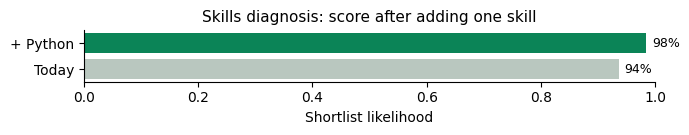

In [16]:
# Try it on the sample files (no upload needed)
jd_text = read_path(SAMPLES / "job_data_analyst.pdf")
report = skill_audit(read_path(SAMPLES / "resumes" / "amina_bello.docx"), jd_text, resume_name="amina_bello.docx")

## Part 6 · Upload a resume and a job description
1. Click **Upload resume(s)**: PDF, DOCX or TXT (you can select several).
2. Click **Upload job description**, **or** paste the job description into the box.
3. Optional: set the candidate's state if the resume doesn't show it.
4. Click **Run skills audit**.

> If the buttons don't appear (e.g. some VS Code or Colab setups), use the *file path* cell below instead.

In [17]:
try:
    import ipywidgets as w
except ImportError:
    w = None
    print("ipywidgets not installed: run  %pip install ipywidgets  and restart the kernel, or use the file-path cell below.")

def _uploaded(up):
    # works with ipywidgets 7 (dict) and 8 (tuple of dicts)
    v = up.value
    if isinstance(v, dict):
        return [(k, bytes(x["content"])) for k, x in v.items()]
    return [(x["name"], bytes(x["content"])) for x in v]

LAST_REPORTS = []
if w:
    resume_up = w.FileUpload(accept=".pdf,.docx,.txt", multiple=True, description="Upload resume(s)",
                             layout=w.Layout(width="220px"))
    jd_up = w.FileUpload(accept=".pdf,.docx,.txt", multiple=False, description="Upload job description",
                         layout=w.Layout(width="220px"))
    jd_box = w.Textarea(placeholder="...or paste the job description here", layout=w.Layout(width="95%", height="120px"))
    state_dd = w.Dropdown(options=["(detect from resume)"] + NG_STATES, description="Candidate state:",
                          style={"description_width": "initial"})
    run_btn = w.Button(description="Run skills audit", button_style="success", icon="search")
    save_cb = w.Checkbox(value=True, description="Save reports to /reports")
    out = w.Output()

    def on_run(_):
        out.clear_output()
        with out:
            try:
                jd_files = _uploaded(jd_up)
                jd = read_document(*jd_files[0]) if jd_files else jd_box.value
                if len(jd.strip()) < 30:
                    print("Please upload or paste a job description."); return
                resumes = _uploaded(resume_up)
                if not resumes:
                    print("Please upload at least one resume."); return
                state = None if state_dd.value.startswith("(") else state_dd.value
                LAST_REPORTS.clear()
                for name, data in resumes:
                    r = skill_audit(read_document(name, data), jd, state_override=state, resume_name=name)
                    LAST_REPORTS.append(r)
                    if save_cb.value:
                        Path("reports").mkdir(exist_ok=True)
                        print("Saved:", export_markdown(r, Path("reports") / f"audit_{Path(name).stem}.md"))
                if len(LAST_REPORTS) > 1:
                    display(Markdown("### Cohort summary")); display(cohort_table(LAST_REPORTS))
            except Exception as e:
                print("⚠️", e)

    run_btn.on_click(on_run)
    display(w.VBox([w.HBox([resume_up, jd_up, state_dd]), jd_box, w.HBox([run_btn, save_cb]), out]))

In [18]:
# # Alternative without widgets: point to files on disk
# RESUME_PATH = SAMPLES / "resumes" / "tunde_okafor.pdf"     # <- change to your resume file
# JD_PATH = SAMPLES / "job_data_analyst.pdf"                  # <- change to your job description file
# STATE = None                                                # e.g. "Lagos" to override detection

# report = skill_audit(read_path(RESUME_PATH), read_path(JD_PATH), state_override=STATE, resume_name=Path(RESUME_PATH).name)

## Part 7 · Cohort skills audit
The same engine, run over a folder of resumes: who is closest to the job, and which gaps are most common (what training to fund).

,resume,candidate,match_%,verdict,missing_required,top_priority_skill
0,amina_bello.docx,Amina Bello,94,Strong match,Python,Python
1,tunde_okafor.pdf,Tunde Okafor,61,Moderate match,Excel,Excel
2,chioma_eze.txt,Chioma Eze,8,Weak match,"Data analysis, Python, SQL",Data analysis
3,musa_ibrahim.txt,Musa Ibrahim,4,Weak match,"Data analysis, Excel, Python, SQL",Data analysis


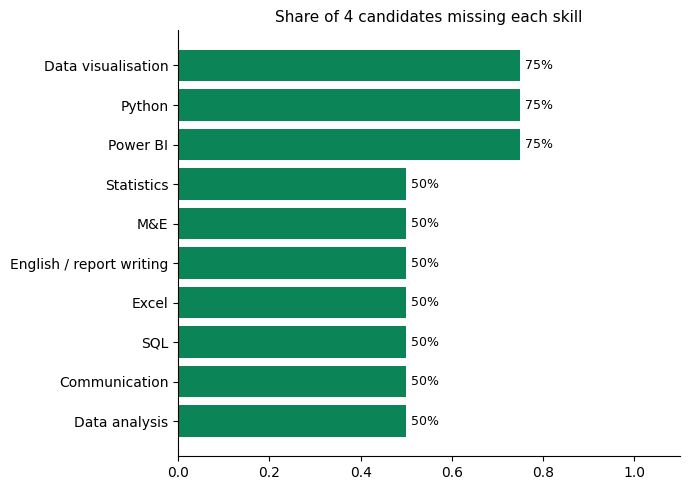

Skills on resumes the taxonomy doesn't recognise yet (possible emerging skills): {'Prompt engineering': np.int64(1)}


In [19]:
def cohort_table(reports):
    return pd.DataFrame([{"resume": r["resume"], "candidate": r["candidate_name"], "match_%": round(r["match_score"] * 100),
                          "verdict": r["verdict"], "missing_required": ", ".join(pretty(s) for s in r["missing_core"]) or "-",
                          "top_priority_skill": pretty(r["priority_skills"][0]["skill"]) if r["priority_skills"] else "-"}
                         for r in reports]).sort_values("match_%", ascending=False).reset_index(drop=True)

def audit_folder(jd_text, folder, state_override=None):
    files = [p for p in Path(folder).iterdir() if p.suffix.lower() in (".pdf", ".docx", ".txt")]
    reports = [skill_audit(read_path(p), jd_text, state_override, p.name, show=False) for p in files]
    display(cohort_table(reports))
    gaps = pd.Series([s for r in reports for s in r["missing_core"] + r["missing_optional"]]).value_counts()
    if len(gaps):
        share = (gaps / len(reports)).sort_values()
        fig, ax = plt.subplots(figsize=(7, 0.4 * len(share) + 1))
        ax.barh([pretty(s) for s in share.index], share.values, color="#0B8457")
        for i, v in enumerate(share.values): ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9)
        ax.set_xlim(0, 1.1); ax.set_title(f"Share of {len(reports)} candidates missing each skill", fontsize=11)
        ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()
    unk = pd.Series([u for r in reports for u in r["unrecognised_skills"]]).value_counts()
    if len(unk):
        print("Skills on resumes the taxonomy doesn't recognise yet (possible emerging skills):", dict(unk))
    return reports

cohort = audit_folder(jd_text, SAMPLES / "resumes")

## Part 8 (optional) · Serve the same engine as a live API
Runs a FastAPI server **inside this notebook** (background thread), the "deploy" step from the talk. Needs `fastapi`, `uvicorn` and `httpx`.

In [20]:
#%pip install -q fastapi uvicorn httpx
import threading
from fastapi import FastAPI
from pydantic import BaseModel
import uvicorn

api = FastAPI(title="Skills Audit API", version=ENGINE.meta["version"])

class AuditRequest(BaseModel):
    resume_text: str
    jd_text: str
    state: str | None = None

@api.get("/health")
def health():
    return {"status": "ok", "model_version": ENGINE.meta["version"]}

@api.post("/skill-audit")
def api_audit(req: AuditRequest):
    return skill_audit(req.resume_text, req.jd_text, req.state, show=False)

PORT = 8765
server = uvicorn.Server(uvicorn.Config(api, host="127.0.0.1", port=PORT, log_level="warning"))
threading.Thread(target=server.run, daemon=True).start()
for _ in range(50):
    if server.started: break
    time.sleep(0.1)
print(f"API running: http://127.0.0.1:{PORT}/docs   (stop with: server.should_exit = True)")

API running: http://127.0.0.1:8765/docs   (stop with: server.should_exit = True)


In [21]:
import httpx
body = {"resume_text": read_path(SAMPLES / "resumes" / "chioma_eze.txt"), "jd_text": jd_text}
lat = []
for _ in range(20):
    t = time.perf_counter(); resp = httpx.post(f"http://127.0.0.1:{PORT}/skill-audit", json=body, timeout=10)
    lat.append((time.perf_counter() - t) * 1000)
r = resp.json()
print(f"{r['candidate_name']} -> {r['job_title']}: {r['match_score']:.0%} ({r['verdict']})")
print(f"missing required: {r['missing_core']} | latency p50 {np.percentile(lat, 50):.1f} ms, max {max(lat):.1f} ms")

Chioma Eze -> Data Analyst - Youth Employment Programme: 8% (Weak match)
missing required: ['data_analysis', 'python', 'sql'] | latency p50 47.1 ms, max 339.0 ms


In [22]:
# Stop the API when you're done
server.should_exit = True